# 04 · Model formation (plan Step 06)

This step fits, for each spread, the in-window seasonal fair value, an AR(1) half-life and z-score, a GARCH(1,1)-t volatility forecast and VECM loadings. It is refit at every month start on the 756 trading days strictly before it, then carried forward day by day with frozen parameters. The logic is in `src/oilrv/model.py` and `scripts/run_model.py`.

All results are a **spot proxy** (PREREGISTRATION.md §5).

$$R_t = S_t - \text{seas}_{m(t)},\qquad z_t = \frac{R_t-\mu}{\sigma},\qquad h = \frac{\ln 2}{-\ln b}$$

where the month effects, μ, σ and the AR(1) coefficient b all come from the fitting window only.

In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import Image
from oilrv.config import ROOT
import sys; sys.path.insert(0, str(ROOT / 'scripts'))
import run_model
summary = run_model.main()                   # about 20 s
T, F = ROOT / 'output/tables', ROOT / 'output/figures'
read = lambda n, **k: pd.read_csv(T / n, **k)

## Parameters by sub-period (medians of the monthly fits)

In [2]:
read('04_param_medians_by_period.csv', index_col=[0, 1]).round(3)

mean      sd  half_life  adf_p  dS_sd  garch_a  \
key               period                                                        
fixed|crack321    2007–2013  13.396   8.264     32.834  0.212  1.561    0.127   
                  2014–2019  18.189   4.039     15.287  0.012  1.154    0.121   
                  2020–2026  26.818   9.775     27.157  0.160  2.268    0.136   
fixed|brent_wti   2007–2013   4.245   7.977     37.671  0.415  1.525    0.114   
                  2014–2019   4.597   3.711     17.031  0.149  1.111    0.046   
                  2020–2026   4.679   3.156      4.146  0.021  1.301    0.276   
fixed|ho_rb       2007–2013   7.665   6.108     16.410  0.008  1.871    0.201   
                  2014–2019   4.070   4.921     15.896  0.013  1.505    0.177   
                  2020–2026   8.965  10.719     21.141  0.131  2.782    0.151   
johansen|crack321 2007–2013   3.420   3.936      6.627  0.000  1.716    0.238   
                  2014–2019  14.005   4.145     10.060  0.001  1.413    0.130   
                  2020–2026  -5.495   4.248      2.580  0.001  2.835    0.278   

                             garch_b  garch_nu  vecm_spread_speed  
key               period                                           
fixed|crack321    2007–2013    0.856     4.818             -0.018  
                  2014–2019    0.709     4.423             -0.034  
                  2020–2026    0.845     4.040             -0.017  
fixed|brent_wti   2007–2013    0.850     7.239             -0.012  
                  2014–2019    0.935     9.375             -0.026  
                  2020–2026    0.647     4.760             -0.105  
fixed|ho_rb       2007–2013    0.758     4.159             -0.032  
                  2014–2019    0.719     4.393             -0.028  
                  2020–2026    0.814     4.419             -0.022  
johansen|crack321 2007–2013    0.714     4.788             -0.068  
                  2014–2019    0.710     4.265             -0.049  
                  2020–2026    0.701     4.087             -0.133

- **Half-lives** of the deseasonalised spreads are about 15–38 days, inside the 5–120 band, except for Brent–WTI in 2020–26.
- **Brent–WTI 2020–26:** the median half-life of 4 days is the April 2020 artefact found in Part 3. That single day dominates every window from June 2020 to April 2023.
- **GARCH:** α + β ≈ 0.83–0.98 (volatility is persistent), with ν ≈ 4–9 Student-t tails.
- **Spread speed** is the daily pull implied by the VECM loadings. −0.02 to −0.03 a day matches half-lives of about 25–35 days.

## Entry gate and signal frequency

In [3]:
read('04_gate_and_signal_rates.csv', index_col=0).round(3)

,months,gate_open_rate,garch_ok_rate,share_days_abs_z_ge_2,share_days_abs_z_ge_4,weights_ok_rate
fixed|crack321,201.0,0.851,0.905,0.193,0.033,NaN
fixed|brent_wti,201.0,0.711,0.731,0.092,0.020,NaN
fixed|ho_rb,201.0,1.000,0.896,0.165,0.037,NaN
johansen|crack321,201.0,0.353,0.880,0.094,0.013,0.582


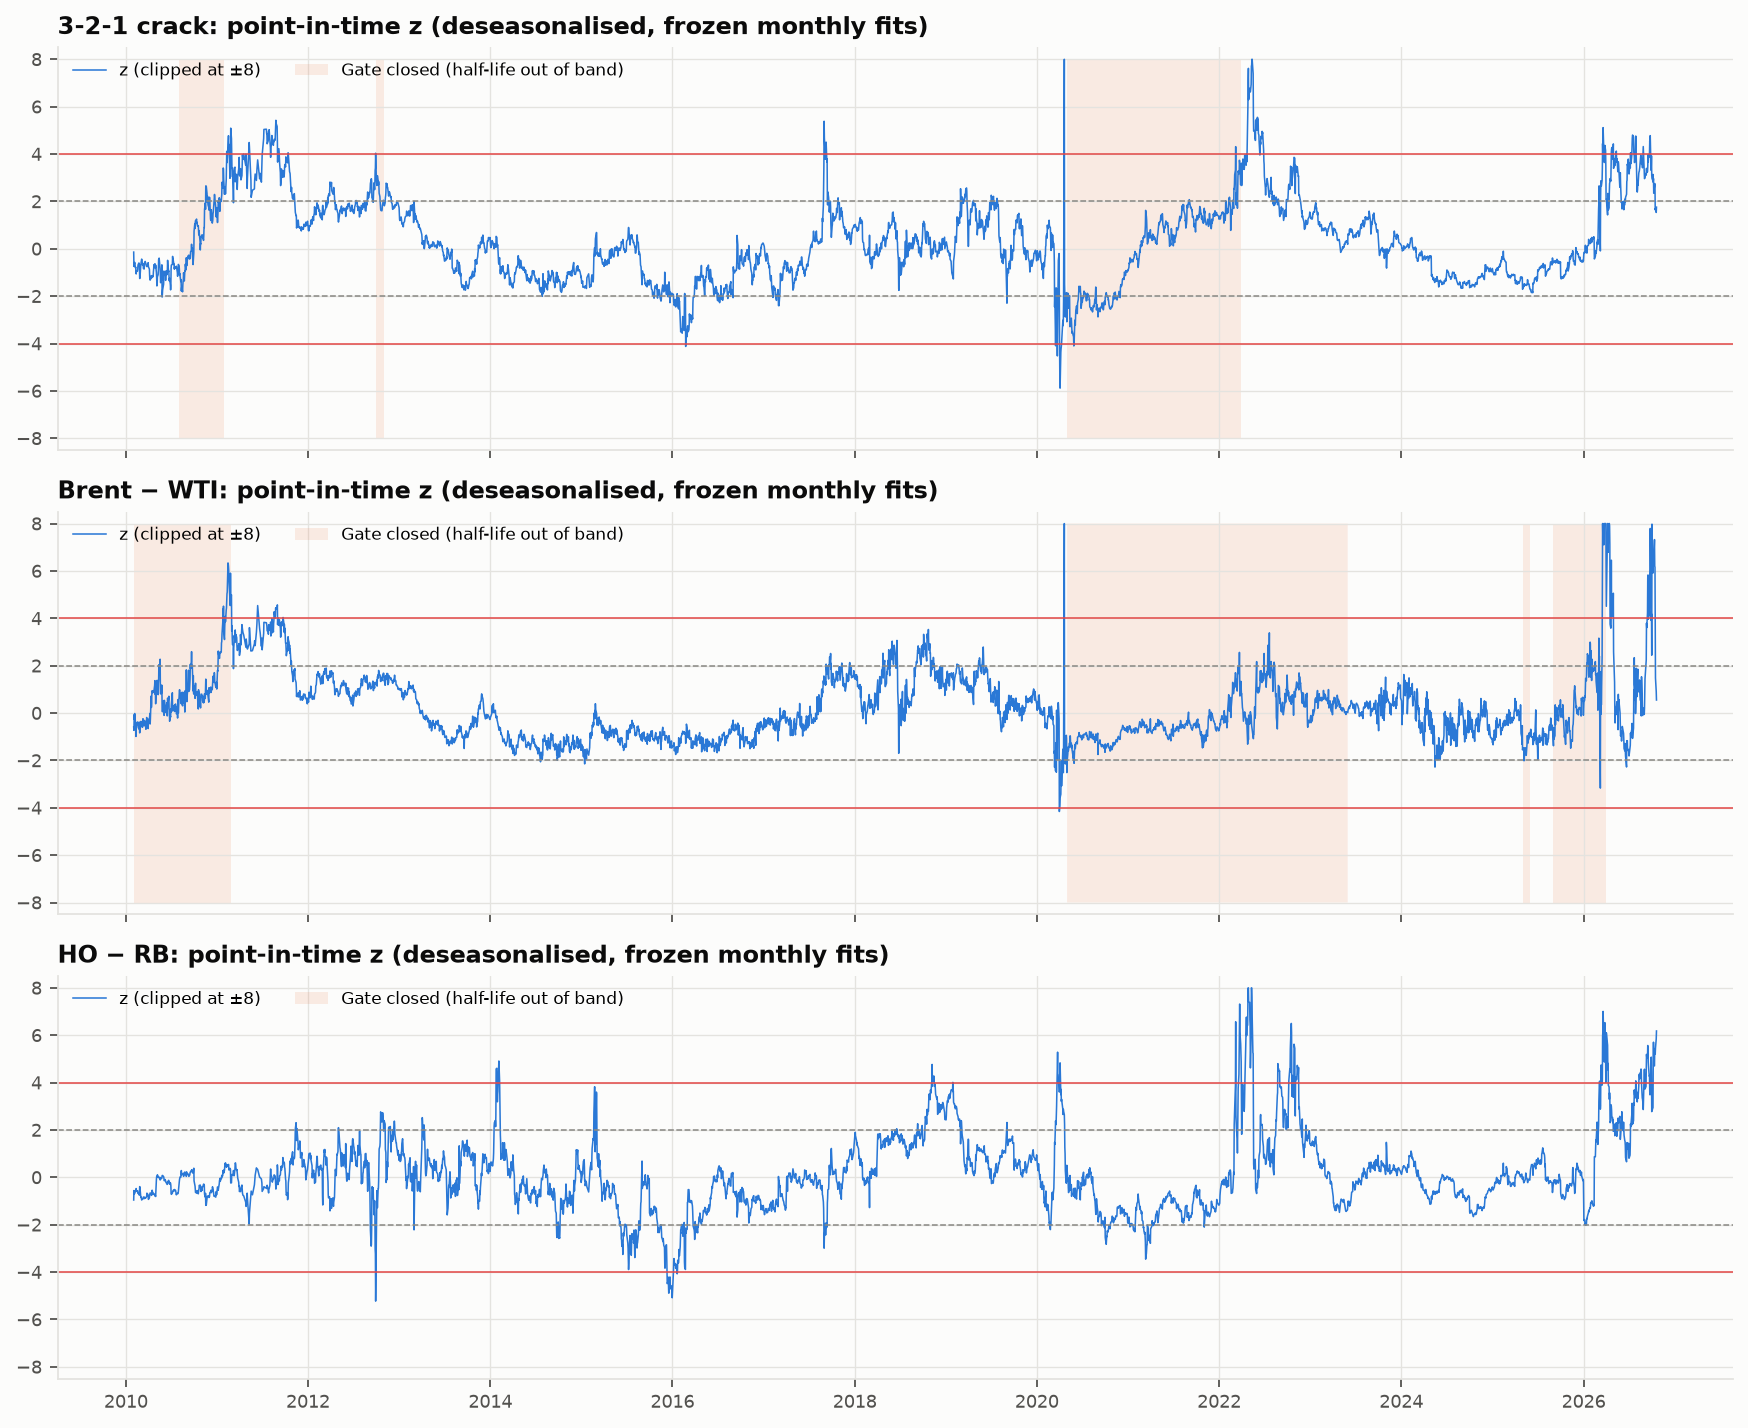

In [4]:
Image(str(F / '04_zscore_and_gates.png'))

- **The half-life gate is open** in 85% of months (crack), 71% (Brent–WTI) and 100% (HO−RB).
- **How often the raw signal fires:** |z| ≥ 2 on 19% (crack), 9% (Brent–WTI) and 17% (HO−RB) of days. |z| ≥ 4, the stop zone, on 2–4% of days.
- **These are raw signal counts**, before re-arming, the blackout and the logit filter. They are not trades.
- **2026 in the plot:**
  - The crack's z went above 4 in March 2026 and has stayed between 2 and 5. This is the "a 3-year z-score has said extreme all year" pattern from the plan.
  - HO−RB is at z ≈ 6 today: past the stop, so no entry is possible.

## GARCH(1,1)-t volatility forecast

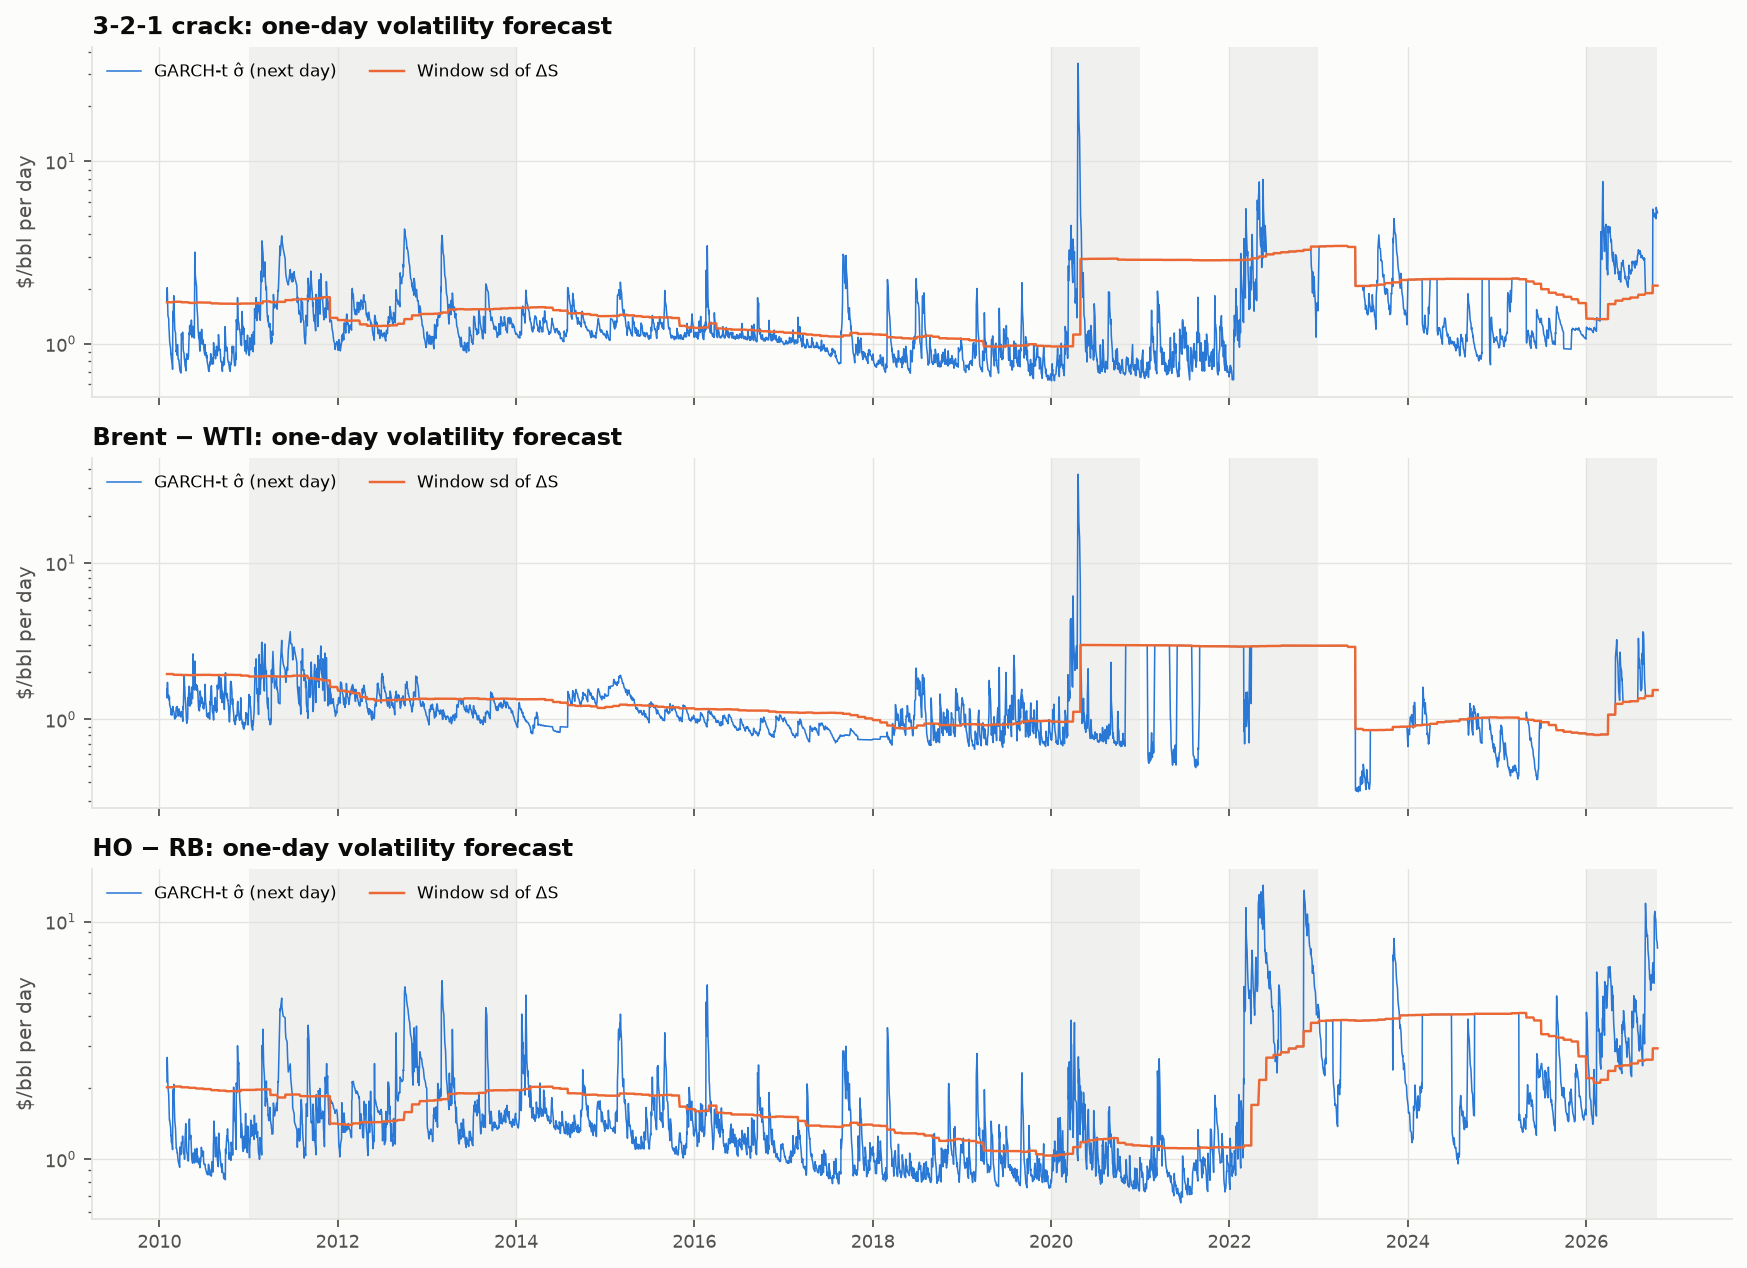

In [5]:
Image(str(F / '04_garch.png'))

In [6]:
read('04_vol_forecast_test.csv', index_col=0).round(4)

,qlike_garch,qlike_const,mean_diff,t_stat,p,n
fixed|crack321,1.6995,3.0229,-1.3234,-1.6135,0.1066,3890.0
fixed|brent_wti,1.6538,2.9394,-1.2856,-1.2864,0.1983,3890.0
fixed|ho_rb,1.9712,2.6717,-0.7005,-3.5611,0.0004,3890.0
johansen|crack321,1.5017,2.0833,-0.5817,-8.4987,0.0000,2238.0


**What this shows**
- **QLIKE comparison:** out of sample, the GARCH forecast beats the constant window sd for every spread. The gain is significant for HO−RB (HAC p < 0.001) and for the Johansen crack. For the fixed crack (p = 0.11) and Brent–WTI (p = 0.20) it is directional only, because a few huge days dominate the loss.
- **Fallbacks.** A GARCH fit that fails or is non-stationary falls back to the window sd. This happens in 9% of crack months, 27% of Brent–WTI months (mostly windows containing April 2020) and 10% of HO−RB months.
- **April 2020 inflates the window sd for 3 years.** The core ladder step sizes on that window sd, so it will run small positions from 2020 to 2023.

## Which leg corrects? VECM with the traded vector

In [7]:
pd.DataFrame(summary['vecm_known_vector']).round(3)

,crack321,brent_wti,ho_rb
alpha_cl,0.008,0.013,NaN
alpha_rb,-0.019,NaN,0.004
alpha_ho,-0.009,NaN,-0.016
share_t_lt_-2_cl,0.000,0.005,NaN
share_t_lt_-2_rb,0.348,NaN,0.000
share_t_lt_-2_ho,0.214,NaN,0.448
share_t_gt_2_cl,0.244,0.333,NaN
share_t_gt_2_rb,0.000,NaN,0.244
share_t_gt_2_ho,0.000,NaN,0.000
spread_speed,-0.023,-0.050,-0.024


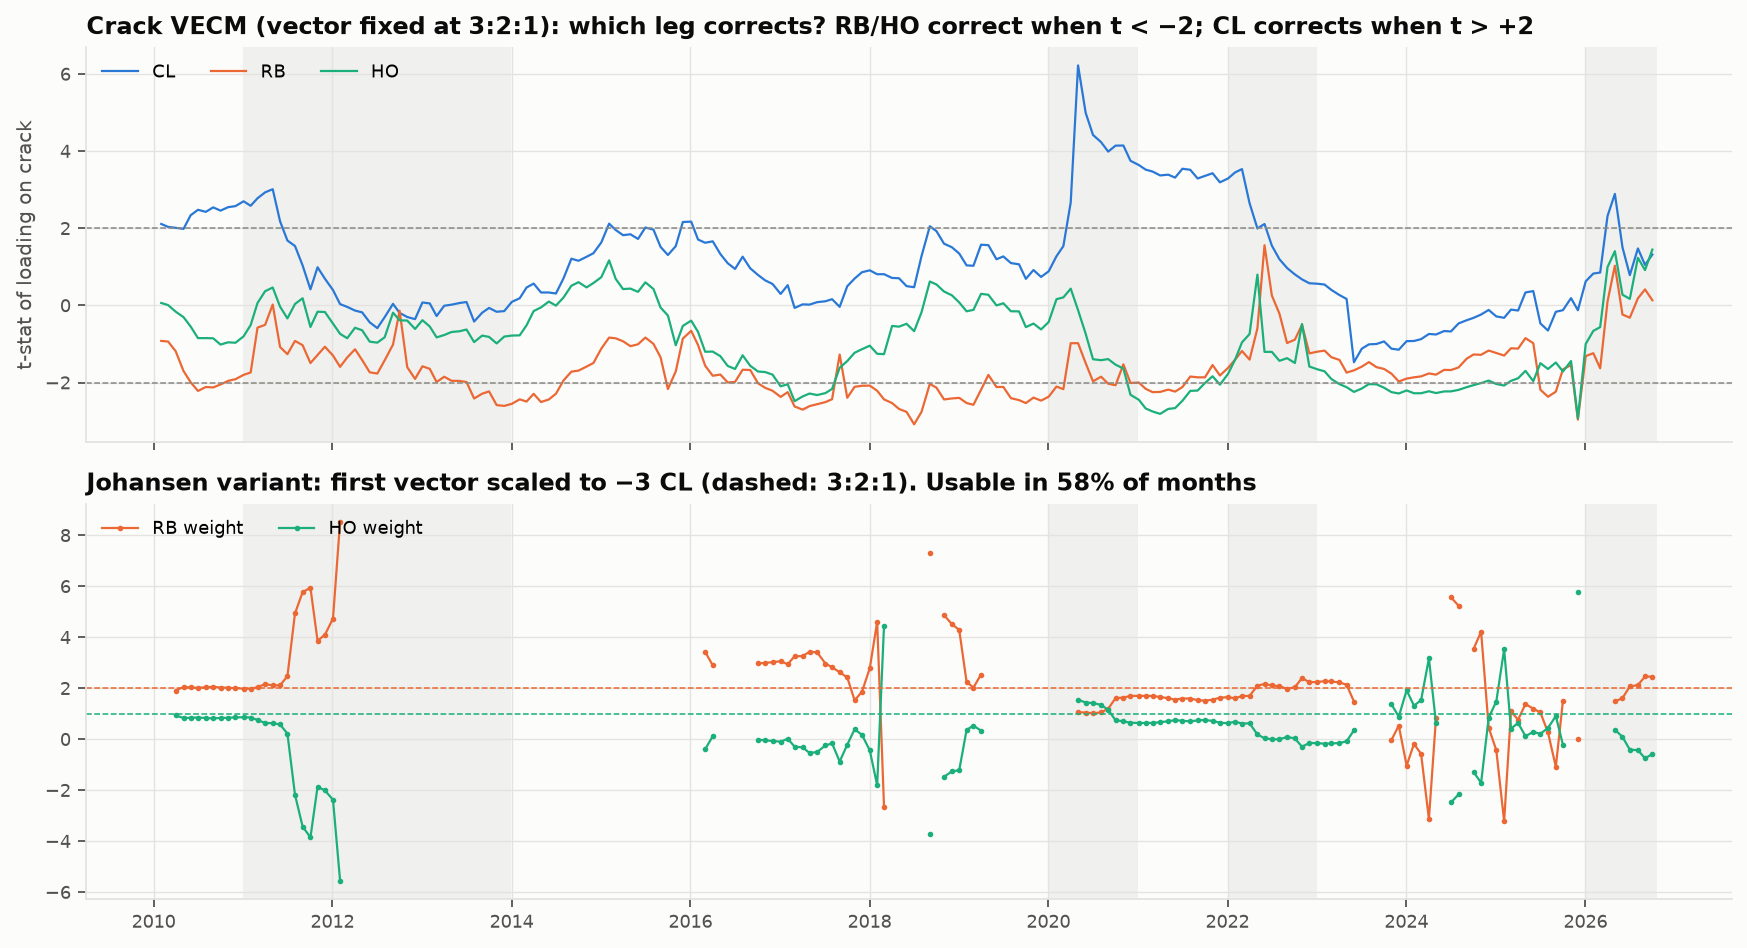

In [8]:
Image(str(F / '04_vecm_and_johansen_weights.png'))

**How to read the loadings.** With the cointegrating vector fixed at the traded weights, a leg with weight wₖ corrects the spread when wₖ·αₖ < 0. For the crack that means RB/HO loadings with t < −2, or a CL loading with t > +2.

- **Crack:**
  - RB does most of the correcting (t < −2 in 35% of months, mostly 2013–23).
  - HO took over in 2021–25 (21% of months).
  - CL corrected in 2020–22 (24% of months). That is partly the April 2020 effect.
  - This broadly matches the plan's prior: *products adjust, crude does not*. So the edge, if there is one, is in the product legs.
- **Brent–WTI:** Brent does most of the correcting (t < −2 in 53% of months), against 33% for WTI. That fits Brent as the seaborne marginal barrel.
- **HO−RB:** HO corrects in 45% of months, RB in 24%.

**Unrestricted VECM** (full sample, rank 2, for comparison):

In [9]:
pd.read_csv(T / '04_vecm_free_full_sample.csv', index_col=[0, 1]).round(4)

ect1    ect2
alpha   cl -0.0149  0.0090
        rb  0.0055 -0.0159
        ho -0.0046  0.0139
alpha_t cl -4.2326  2.2588
        rb  1.3600 -3.4888
        ho -0.9791  2.6164
beta    cl  1.0000 -0.0000
        rb -0.0000  1.0000
        ho -0.5763 -0.7376

## Johansen variant (crack only, robustness, not gated)
- **The vector is often unusable.** The first Johansen vector, scaled to −3 CL, gives a usable weight set in only 58% of months. A month has none when the rank is 0, or when the CL loading is near 0 and a scaled weight would exceed 10. In those months the variant's gate is closed.
- **When it is usable, it is erratic.** It is close to 3:2:1 in 2010–11 and 2020–23, but the HO weight swings between −5 and +6 elsewhere.
- **Combined gate:** open in only 35% of months. Part 3 predicted this from the unstable Johansen rank.

## In-window seasonal effects

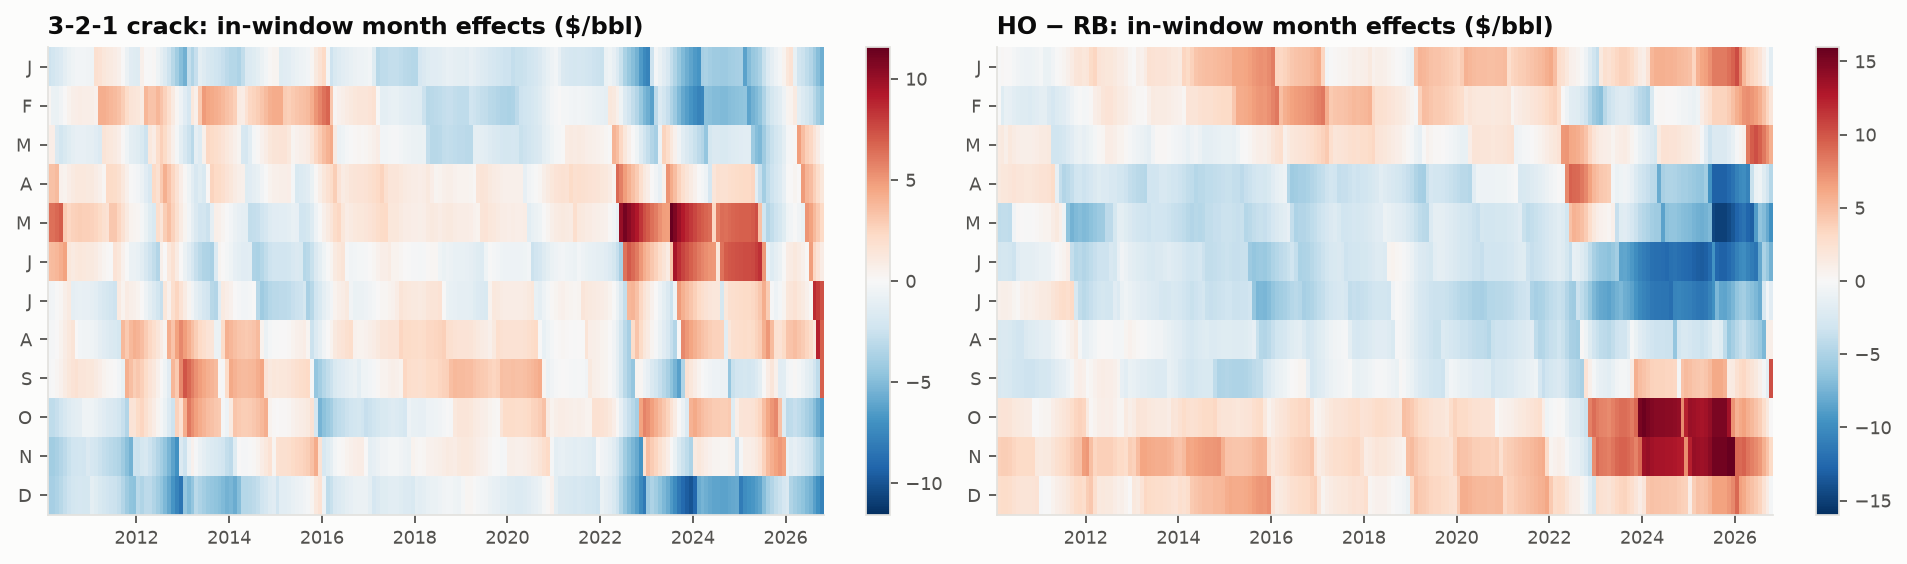

In [10]:
Image(str(F / '04_seasonal_effects.png'))

- **The seasonal correction is stable in shape.** It always takes the crack's summer premium and HO−RB's winter premium out of the fair value. It does grow in size once 2022 enters the window.
- Because the month means are estimated inside each window, a 2022-style summer surge is never subtracted before it has been seen.

## Latest point-in-time state (spot, 20 Oct 2026)

In [11]:
read('04_latest_state.csv', index_col=0)

,date,S,z,sigma_next,dS_sd,half_life,adf_p,gate,sigma_pct_in_history
fixed|crack321,2026-10-20,46.936000,1.758001,5.217260,2.081841,64.915911,0.980410,True,0.992911
fixed|brent_wti,2026-10-20,7.330000,0.550773,1.541046,1.541046,10.347354,0.046135,True,0.781716
fixed|ho_rb,2026-10-20,99.456000,6.179545,7.732159,2.925485,34.471236,0.586169,True,0.986067
johansen|crack321,2026-10-20,-51.668256,-6.892051,5.215250,2.259427,6.160721,0.000047,True,0.571743


**The current state, read with Part 7's switch-on triggers in mind**
- **Crack:** z ≈ 1.8, with the window sd now including 2026. Its GARCH σ̂ ≈ \$5.2/bbl a day is in the 99th percentile of its own history. Worked example B in the plan used σ̂ = \$2.50; the actual σ̂ is about twice that, so the sizing rule would give 0 units.
- **HO−RB:** z ≈ 6.2, beyond the stop. σ̂ is in the 99th percentile.
- **Brent–WTI:** z ≈ 0.6, so there is no signal.

**Next:** Part 5 (logit filter) builds episodes from these frozen z-paths.